# Battery and heating

## Summary
**1**. **Data Cleaning (Ad-hoc Analysis)**

- Imported necessary libraries and datasets, checked dataframes, and added an indicator column, 'Trip', to identify entries in the trip dataframes.
Removed irrelevant columns, renamed an unidentified column, and handled null values in the 'Overview' dataframe. Created a new dataframe, 'overview_new', with treated NaN indices.
- Converted categorical columns from float64 to object dtype.
- Concatenated 70 trip dataframes vertically, verified data types, and checked unique values.
- Converted columns with four or fewer unique values to object type, calculated NaN percentages, and dropped columns with more than 10% missing values.
- Merged 'overview_new' with the concatenated trip data on the 'Trip' column.
  
**2**. **Feature Engineering**

- Applied one-hot encoding to categorical columns.
- Replaced instances of the unique value NaN in the 'Note' column with 'Other'.
  
**3**. **Exploratory Data Analysis (EDA)**

- Visualized relationships with a scatter plot matrix.
- Conducted statistical analysis on numerical variables.
- Assessed multicollinearity using a correlation matrix and heatmap.
  
**4**. **Predictive Modeling with Machine Learning**

- Split data into training and testing sets.
- Built a logistic regression model with X_train and y_train, making predictions and calculating probabilities on X_test.
- Evaluated model performance using accuracy, sensitivity, recall, and R² metrics.
- Displayed feature coefficients and names, and visualized the results in a plot.

**5**. **Future Recommendations**

- **Alternative Model Comparison**: Implement a decision tree model as an alternative to the logistic regression model, enabling comparison of results and selection of the best-performing model.

- **Data Exploration and Model Selection**: Perform stratified random sampling and plot a scatter plot matrix to understand data separation. This will inform the decision on whether linear or non-linear models are more suitable.

- **K-Fold Cross Validation**: Use K-fold cross-validation (likely `k=10`) to achieve a more generalized accuracy metric.

- **Feature Engineering for Numerical Columns**: Convert specific numerical columns to categorical variables where apprsackets) to capture non-linear relationships.

- **Pruning of Less Desirable Features**: Identify and remove less relevant features to improve model generalization and minimize potential bias.

- **Identification of Key Variables**: Determine important variables that would be valuable in future data collection and experimental design, focusing on insights for enhancing predictive power.

- **Application to Battery Heating Prediction**: Utilize this framework as a baseline for developing models aimed at predicting battery heating, potentially adapting feature engineering, data exploration, and validation steps specific to this application.

## Data Cleaning

### Importing requisite libraries

In [14]:
# importing libraries saari libraries
import pandas as pd
from string import ascii_letters
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.metrics import r2_score

In [16]:
# Loading overview dataset 
overview = pd.read_csv('C:/Users/Anurodh/Battery-ML project/Overview.csv', encoding = "ISO-8859-1")

In [18]:
# checking head
overview.head()

,Trip,Date,Route/Area,Weather,Battery Temperature (Start) [°C],Battery Temperature (End),Battery State of Charge (Start),Battery State of Charge (End),Unnamed: 8,Ambient Temperature (Start) [°C],Target Cabin Temperature,Distance [km],Duration [min],Unnamed: 13,Fan,Note
0,TripA01,2019-06-25_13-21-14,Munich East,sunny,21.0,22.0,86.3%,80.3%,6.0%,25.5,23.0,7.43,16.82,NaN,"Automatic, Level 1",NaN
1,TripA02,2019-06-25_14-05-31,Munich East,sunny,23.0,26.0,80.3%,67.3%,13.0%,32.0,23.0,23.51,23.55,NaN,"Automatic, Level 1",Target Cabin Temperature changed
2,TripA03,2019-06-28_10-02-15,Munich East,sunny,24.0,25.0,83.5%,75.1%,8.4%,21.5,27.0,12.82,11.18,NaN,"Automatic, Level 1",Target Cabin Temperature changed
3,TripA04,2019-06-28_10-13-30,Munich East,sunny,25.0,27.0,75.1%,66.7%,8.4%,24.0,22.0,10.73,6.87,NaN,"Automatic, Level 1",NaN
4,TripA05,2019-06-28_10-20-26,Munich East,sunny,27.0,27.0,66.7%,60.2%,6.5%,24.5,24.0,12.39,22.78,NaN,"Automatic, Level 1",NaN


In [20]:
# Checking the df overview
overview.shape

(73, 16)

In [22]:
# Checking columns in the df overview
overview.columns

Index(['Trip', 'Date', 'Route/Area', 'Weather',
       'Battery Temperature (Start) [°C]', 'Battery Temperature (End)',
       'Battery State of Charge (Start)', 'Battery State of Charge (End)',
       'Unnamed: 8', 'Ambient Temperature (Start) [°C]',
       'Target Cabin Temperature', 'Distance [km]', 'Duration [min]',
       'Unnamed: 13', 'Fan', 'Note'],
      dtype='object')

In [24]:
# loading other df's
import warnings
warnings.filterwarnings("ignore", module="pandas") 

tripa01 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA01.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa02 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA02.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa03 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA03.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa04 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA04.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa05 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA05.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa06 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA06.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa07 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA07.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa08 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA08.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa09 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA09.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa10 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA10.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa11 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA11.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa12 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA12.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa13 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA13.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa14 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA14.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa15 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA15.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa16 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA16.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa17 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA17.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa18 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA18.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa19 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA19.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa20 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA20.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa21 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA21.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa22 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA22.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa23 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA23.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa24 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA24.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa25 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA25.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa26 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA26.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa27 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA27.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa28 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA28.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa29 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA29.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa30 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA30.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa31 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA31.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripa32 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA32.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb01 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB01.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb02 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB02.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb03 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB03.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb04 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB04.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb05 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB05.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb06 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB06.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb07 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB07.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb08 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB08.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb09 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB09.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb10 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB10.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb11 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB11.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb12 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB12.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb13 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB13.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb14 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB14.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb15 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB15.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb16 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB16.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb17 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB17.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb18 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB18.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb19 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB19.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb20 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB20.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb21 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB21.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb22 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB22.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb23 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB23.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb24 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB24.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb25 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB25.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb26 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB26.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb27 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB27.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb28 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB28.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb29 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB29.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb30 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB30.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb31 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB31.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb32 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB32.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb33 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB33.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb34 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB34.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb35 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB35.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb36 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB36.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb37 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB37.csv',header = 0, sep = None, encoding = "ISO-8859-1")
tripb38 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripB38.csv',header = 0, sep = None, encoding = "ISO-8859-1")

C:\Users\Anurodh\AppData\Local\Temp\ipykernel_5404\1051714905.py:5: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support sep=None with delim_whitespace=False; you can avoid this warning by specifying engine='python'.
  tripa01 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA01.csv',header = 0, sep = None, encoding = "ISO-8859-1")
C:\Users\Anurodh\AppData\Local\Temp\ipykernel_5404\1051714905.py:6: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support sep=None with delim_whitespace=False; you can avoid this warning by specifying engine='python'.
  tripa02 = pd.read_csv('C:/Users/Anurodh/Battery-ML project/TripA02.csv',header = 0, sep = None, encoding = "ISO-8859-1")
C:\Users\Anurodh\AppData\Local\Temp\ipykernel_5404\1051714905.py:7: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support sep=None with delim_whitespace=False; you can avoid this warning by specifying engine

In [26]:
# Checking df tripa01
tripa01.head()

,Time [s],Velocity [km/h],Elevation [m],Throttle [%],Motor Torque [Nm],Longitudinal Acceleration [m/s^2],Regenerative Braking Signal,Battery Voltage [V],Battery Current [A],Battery Temperature [°C],...,AirCon Power [kW],Heater Signal,Heater Voltage [V],Heater Current [A],Ambient Temperature [°C],Coolant Temperature Heatercore [°C],Requested Coolant Temperature [°C],Coolant Temperature Inlet [°C],Heat Exchanger Temperature [°C],Cabin Temperature Sensor [°C]
0,0.0,0.0,574.0,0.0,0.0,-0.03,0.0,391.4,-2.20,21.0,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5
1,0.1,0.0,574.0,0.0,0.0,0.00,0.0,391.4,-2.21,21.0,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5
2,0.2,0.0,574.0,0.0,0.0,-0.01,0.0,391.4,-2.26,21.0,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5
3,0.3,0.0,574.0,0.0,0.0,-0.03,0.0,391.4,-2.30,21.0,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5
4,0.4,0.0,574.0,0.0,0.0,-0.03,0.0,391.4,-2.30,21.0,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5


In [28]:
# checking names of the columns in the df
tripa01.columns

Index(['Time [s]', 'Velocity [km/h]', 'Elevation [m]', 'Throttle [%]',
       'Motor Torque [Nm]', 'Longitudinal Acceleration [m/s^2]',
       'Regenerative Braking Signal ', 'Battery Voltage [V]',
       'Battery Current [A]', 'Battery Temperature [°C]',
       'max. Battery Temperature [°C]', 'SoC [%]', 'displayed SoC [%]',
       'min. SoC [%]', 'max. SoC [%)', 'Heating Power CAN [kW]',
       'Heating Power LIN [W]', 'Requested Heating Power [W]',
       'AirCon Power [kW]', 'Heater Signal', 'Heater Voltage [V]',
       'Heater Current [A]', 'Ambient Temperature [°C]',
       'Coolant Temperature Heatercore [°C]',
       'Requested Coolant Temperature [°C]', 'Coolant Temperature Inlet [°C]',
       'Heat Exchanger Temperature [°C]', 'Cabin Temperature Sensor [°C]'],
      dtype='object')

In [30]:
# tripa01 no. of rows and columns
tripa01.shape

(10090, 28)

In [32]:
# Adding an indicator column to the df TripA01 'Trip'
tripa01.insert(0, 'Trip', 'TripA01')

In [34]:
# checking
tripa01.head()

,Trip,Time [s],Velocity [km/h],Elevation [m],Throttle [%],Motor Torque [Nm],Longitudinal Acceleration [m/s^2],Regenerative Braking Signal,Battery Voltage [V],Battery Current [A],...,AirCon Power [kW],Heater Signal,Heater Voltage [V],Heater Current [A],Ambient Temperature [°C],Coolant Temperature Heatercore [°C],Requested Coolant Temperature [°C],Coolant Temperature Inlet [°C],Heat Exchanger Temperature [°C],Cabin Temperature Sensor [°C]
0,TripA01,0.0,0.0,574.0,0.0,0.0,-0.03,0.0,391.4,-2.20,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5
1,TripA01,0.1,0.0,574.0,0.0,0.0,0.00,0.0,391.4,-2.21,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5
2,TripA01,0.2,0.0,574.0,0.0,0.0,-0.01,0.0,391.4,-2.26,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5
3,TripA01,0.3,0.0,574.0,0.0,0.0,-0.03,0.0,391.4,-2.30,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5
4,TripA01,0.4,0.0,574.0,0.0,0.0,-0.03,0.0,391.4,-2.30,...,0.4,1,0,0,25.5,0,0,0,30.5,24.5


> **Added indicator column to create a mutual column where all the datasets could be joined**

In [36]:
# Adding 'indicator column' to each df
tripa02.insert(0, 'Trip', 'TripA02')
tripa03.insert(0, 'Trip', 'TripA03')
tripa04.insert(0, 'Trip', 'TripA04')
tripa05.insert(0, 'Trip', 'TripA05')
tripa06.insert(0, 'Trip', 'TripA06')
tripa07.insert(0, 'Trip', 'TripA07')
tripa08.insert(0, 'Trip', 'TripA08')
tripa09.insert(0, 'Trip', 'TripA09')
tripa10.insert(0, 'Trip', 'TripA10')
tripa11.insert(0, 'Trip', 'TripA11')
tripa12.insert(0, 'Trip', 'TripA12')
tripa13.insert(0, 'Trip', 'TripA13')
tripa14.insert(0, 'Trip', 'TripA14')
tripa15.insert(0, 'Trip', 'TripA15')
tripa16.insert(0, 'Trip', 'TripA16')
tripa17.insert(0, 'Trip', 'TripA17')
tripa18.insert(0, 'Trip', 'TripA18')
tripa19.insert(0, 'Trip', 'TripA19')
tripa20.insert(0, 'Trip', 'TripA20')
tripa21.insert(0, 'Trip', 'TripA21')
tripa22.insert(0, 'Trip', 'TripA22')
tripa23.insert(0, 'Trip', 'TripA23')
tripa24.insert(0, 'Trip', 'TripA24')
tripa25.insert(0, 'Trip', 'TripA25')
tripa26.insert(0, 'Trip', 'TripA26')
tripa27.insert(0, 'Trip', 'TripA27')
tripa28.insert(0, 'Trip', 'TripA28')
tripa29.insert(0, 'Trip', 'TripA29')
tripa30.insert(0, 'Trip', 'TripA30')
tripa31.insert(0, 'Trip', 'TripA31')
tripa32.insert(0, 'Trip', 'TripA32')
tripb01.insert(0, 'Trip', 'TripB01')
tripb02.insert(0, 'Trip', 'TripB02')
tripb03.insert(0, 'Trip', 'TripB03')
tripb04.insert(0, 'Trip', 'TripB04')
tripb05.insert(0, 'Trip', 'TripB05')
tripb06.insert(0, 'Trip', 'TripB06')
tripb07.insert(0, 'Trip', 'TripB07')
tripb08.insert(0, 'Trip', 'TripB08')
tripb09.insert(0, 'Trip', 'TripB09')
tripb10.insert(0, 'Trip', 'TripB10')
tripb11.insert(0, 'Trip', 'TripB11')
tripb12.insert(0, 'Trip', 'TripB12')
tripb13.insert(0, 'Trip', 'TripB13')
tripb14.insert(0, 'Trip', 'TripB14')
tripb15.insert(0, 'Trip', 'TripB15')
tripb16.insert(0, 'Trip', 'TripB16')
tripb17.insert(0, 'Trip', 'TripB17')
tripb18.insert(0, 'Trip', 'TripB18')
tripb19.insert(0, 'Trip', 'TripB19')
tripb20.insert(0, 'Trip', 'TripB20')
tripb21.insert(0, 'Trip', 'TripB21')
tripb22.insert(0, 'Trip', 'TripB22')
tripb23.insert(0, 'Trip', 'TripB23')
tripb24.insert(0, 'Trip', 'TripB24')
tripb25.insert(0, 'Trip', 'TripB25')
tripb26.insert(0, 'Trip', 'TripB26')
tripb27.insert(0, 'Trip', 'TripB27')
tripb28.insert(0, 'Trip', 'TripB28')
tripb29.insert(0, 'Trip', 'TripB29')
tripb30.insert(0, 'Trip', 'TripB30')
tripb31.insert(0, 'Trip', 'TripB31')
tripb32.insert(0, 'Trip', 'TripB32')
tripb33.insert(0, 'Trip', 'TripB33')
tripb34.insert(0, 'Trip', 'TripB34')
tripb35.insert(0, 'Trip', 'TripB35')
tripb36.insert(0, 'Trip', 'TripB36')
tripb37.insert(0, 'Trip', 'TripB37')
tripb38.insert(0, 'Trip', 'TripB38')

# 1. Data Cleaning (ad hoc analysis)

In [42]:
# Cleaning 'overview' before merging
overview.head()

,Trip,Date,Route/Area,Weather,Battery Temperature (Start) [°C],Battery Temperature (End),Battery State of Charge (Start),Battery State of Charge (End),Unnamed: 8,Ambient Temperature (Start) [°C],Target Cabin Temperature,Distance [km],Duration [min],Unnamed: 13,Fan,Note
0,TripA01,2019-06-25_13-21-14,Munich East,sunny,21.0,22.0,86.3%,80.3%,6.0%,25.5,23.0,7.43,16.82,NaN,"Automatic, Level 1",NaN
1,TripA02,2019-06-25_14-05-31,Munich East,sunny,23.0,26.0,80.3%,67.3%,13.0%,32.0,23.0,23.51,23.55,NaN,"Automatic, Level 1",Target Cabin Temperature changed
2,TripA03,2019-06-28_10-02-15,Munich East,sunny,24.0,25.0,83.5%,75.1%,8.4%,21.5,27.0,12.82,11.18,NaN,"Automatic, Level 1",Target Cabin Temperature changed
3,TripA04,2019-06-28_10-13-30,Munich East,sunny,25.0,27.0,75.1%,66.7%,8.4%,24.0,22.0,10.73,6.87,NaN,"Automatic, Level 1",NaN
4,TripA05,2019-06-28_10-20-26,Munich East,sunny,27.0,27.0,66.7%,60.2%,6.5%,24.5,24.0,12.39,22.78,NaN,"Automatic, Level 1",NaN


In [44]:
# Dropping unnamed 13 as it has nan values in each row
del overview['Unnamed: 13']

In [46]:
# Renaming column as 'Depth of Discharge'
overview.rename(columns={'Unnamed: 8': 'Depth of Discharge'}, inplace=True)

In [48]:
# Replacing 'NaN' by 'Other' in Note column
overview['Note'] = overview['Note'].fillna('Other')
overview.head()

,Trip,Date,Route/Area,Weather,Battery Temperature (Start) [°C],Battery Temperature (End),Battery State of Charge (Start),Battery State of Charge (End),Depth of Discharge,Ambient Temperature (Start) [°C],Target Cabin Temperature,Distance [km],Duration [min],Fan,Note
0,TripA01,2019-06-25_13-21-14,Munich East,sunny,21.0,22.0,86.3%,80.3%,6.0%,25.5,23.0,7.43,16.82,"Automatic, Level 1",Other
1,TripA02,2019-06-25_14-05-31,Munich East,sunny,23.0,26.0,80.3%,67.3%,13.0%,32.0,23.0,23.51,23.55,"Automatic, Level 1",Target Cabin Temperature changed
2,TripA03,2019-06-28_10-02-15,Munich East,sunny,24.0,25.0,83.5%,75.1%,8.4%,21.5,27.0,12.82,11.18,"Automatic, Level 1",Target Cabin Temperature changed
3,TripA04,2019-06-28_10-13-30,Munich East,sunny,25.0,27.0,75.1%,66.7%,8.4%,24.0,22.0,10.73,6.87,"Automatic, Level 1",Other
4,TripA05,2019-06-28_10-20-26,Munich East,sunny,27.0,27.0,66.7%,60.2%,6.5%,24.5,24.0,12.39,22.78,"Automatic, Level 1",Other


In [54]:
# checking null values in the df
overview.isna().any()

Trip                                 True
Date                                 True
Route/Area                           True
Weather                              True
Battery Temperature (Start) [°C]     True
Battery Temperature (End)            True
Battery State of Charge (Start)      True
Battery State of Charge (End)        True
Depth of Discharge                   True
Ambient Temperature (Start) [°C]     True
Target Cabin Temperature             True
Distance [km]                        True
Duration [min]                       True
Fan                                  True
Note                                False
dtype: bool

In [56]:
# checking number of NaN values in each column
overview.isna().sum()

Trip                                3
Date                                3
Route/Area                          3
Weather                             3
Battery Temperature (Start) [°C]    3
Battery Temperature (End)           3
Battery State of Charge (Start)     3
Battery State of Charge (End)       3
Depth of Discharge                  3
Ambient Temperature (Start) [°C]    3
Target Cabin Temperature            3
Distance [km]                       3
Duration [min]                      3
Fan                                 3
Note                                0
dtype: int64

In [58]:
# Checking missing indices in the df overview
missing_indices_overview = overview[overview.isnull().any(axis=1)].index
missing_indices_overview

Index([32, 33, 72], dtype='int64')

In [60]:
# Check specific rows (33) with NaN values
overview.iloc[32,:]

Trip                                  NaN
Date                                  NaN
Route/Area                            NaN
Weather                               NaN
Battery Temperature (Start) [°C]      NaN
Battery Temperature (End)             NaN
Battery State of Charge (Start)       NaN
Battery State of Charge (End)         NaN
Depth of Discharge                    NaN
Ambient Temperature (Start) [°C]      NaN
Target Cabin Temperature              NaN
Distance [km]                         NaN
Duration [min]                        NaN
Fan                                   NaN
Note                                Other
Name: 32, dtype: object

In [62]:
# Removing Nan rows as they are empty rows in the csv file
overview_new = overview.dropna()
overview_new.isna().sum()

Trip                                0
Date                                0
Route/Area                          0
Weather                             0
Battery Temperature (Start) [°C]    0
Battery Temperature (End)           0
Battery State of Charge (Start)     0
Battery State of Charge (End)       0
Depth of Discharge                  0
Ambient Temperature (Start) [°C]    0
Target Cabin Temperature            0
Distance [km]                       0
Duration [min]                      0
Fan                                 0
Note                                0
dtype: int64

> Created **overview_new** where I removed the rows which had NaN values. The rows were empty. This makes the df complete

In [46]:
# Checking dtypes of the columns in 'overview_new'
overview_new.dtypes

Trip                                 object
Date                                 object
Route/Area                           object
Weather                              object
Battery Temperature (Start) [°C]    float64
Battery Temperature (End)           float64
Battery State of Charge (Start)      object
Battery State of Charge (End)        object
Variable                             object
Ambient Temperature (Start) [°C]    float64
Target Cabin Temperature            float64
Distance [km]                       float64
Duration [min]                      float64
Fan                                  object
Note                                 object
dtype: object

> **Here 'Route/Area', 'Weather', 'Fan' and 'Note' are categorical.**
> **The '%' has changed the dtype of three numerical columns. Removing the '%' and the changing the dtype of the respective columns.**

In [49]:
# Removing % from the columns to change dtype of the columns of interest
# Using a list to access multiple columns
overview_new[['Battery State of Charge (Start)', 'Battery State of Charge (End)', 'Variable']] = \
    overview_new[['Battery State of Charge (Start)', 'Battery State of Charge (End)', 'Variable']].apply(lambda x: x.str.rstrip('%'))

C:\Users\Anurodh\AppData\Local\Temp\ipykernel_16088\2652509275.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  overview_new[['Battery State of Charge (Start)', 'Battery State of Charge (End)', 'Variable']] = \


In [51]:
# Changing dtype from object to numeric
overview_new['Battery State of Charge (Start)'] = pd.to_numeric(overview_new['Battery State of Charge (Start)'])
overview_new['Battery State of Charge (End)'] = pd.to_numeric(overview_new['Battery State of Charge (End)'])                                                         
overview_new['Variable'] = pd.to_numeric(overview_new['Variable'])

overview_new.dtypes

C:\Users\Anurodh\AppData\Local\Temp\ipykernel_16088\3482905506.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  overview_new['Battery State of Charge (Start)'] = pd.to_numeric(overview_new['Battery State of Charge (Start)'])
C:\Users\Anurodh\AppData\Local\Temp\ipykernel_16088\3482905506.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  overview_new['Battery State of Charge (End)'] = pd.to_numeric(overview_new['Battery State of Charge (End)'])
C:\Users\Anurodh\AppData\Local\Temp\ipykernel_16088\34829055

Trip                                 object
Date                                 object
Route/Area                           object
Weather                              object
Battery Temperature (Start) [°C]    float64
Battery Temperature (End)           float64
Battery State of Charge (Start)     float64
Battery State of Charge (End)       float64
Variable                            float64
Ambient Temperature (Start) [°C]    float64
Target Cabin Temperature            float64
Distance [km]                       float64
Duration [min]                      float64
Fan                                  object
Note                                 object
dtype: object

In [53]:
# Check NaN values in the df
overview_new.isna().sum()

Trip                                0
Date                                0
Route/Area                          0
Weather                             0
Battery Temperature (Start) [°C]    0
Battery Temperature (End)           0
Battery State of Charge (Start)     0
Battery State of Charge (End)       0
Variable                            0
Ambient Temperature (Start) [°C]    0
Target Cabin Temperature            0
Distance [km]                       0
Duration [min]                      0
Fan                                 0
Note                                0
dtype: int64

> **overview_new** is NaN free and changed the dtypes of the columns where the dtype was wrong

## Cleaning and merging the trip df's

In [57]:
# concatenating trips df's before merging with 'Overview_new'
vertical_concat_trips = pd.concat([tripa01, tripa02,tripa03, tripa04, tripa05, tripa06, tripa07, tripa08, tripa09, tripa10, tripa11, tripa12, tripa13, tripa14, tripa15, tripa16, tripa17, tripa18, tripa19, tripa20, tripa21, tripa22, tripa23, tripa24, tripa25, tripa26, tripa27, tripa28, tripa29, tripa30, tripa31, tripa32, tripb01, tripb02, tripb03, tripb04, tripb05, tripb06, tripb07, tripb08, tripb09, tripb10, tripb11, tripb12, tripb13, tripb14, tripb15, tripb16, tripb17, tripb18, tripb19, tripb20, tripb21, tripb22, tripb23, tripb24, tripb25, tripb26, tripb27, tripb28, tripb29, tripb30, tripb31, tripb32, tripb33, tripb34, tripb35, tripb36, tripb37, tripb38], axis=0)

In [59]:
# Check length of concatted columns
len(vertical_concat_trips.columns)

51

In [61]:
# % of missing values
percent_missing = vertical_concat_trips.isnull().sum() * 100 / len(vertical_concat_trips)
percent_missing

Trip                                       0.000000
Time [s]                                   0.000000
Velocity [km/h]                            1.500649
Elevation [m]                              0.000000
Throttle [%]                               0.000000
Motor Torque [Nm]                          0.000000
Longitudinal Acceleration [m/s^2]          0.000000
Regenerative Braking Signal                0.000000
Battery Voltage [V]                        0.000000
Battery Current [A]                        0.000000
Battery Temperature [°C]                   0.000000
max. Battery Temperature [°C]              0.000000
SoC [%]                                    2.812678
displayed SoC [%]                          2.812769
min. SoC [%]                               2.812678
max. SoC [%)                               2.812769
Heating Power CAN [kW]                     0.000000
Heating Power LIN [W]                     28.369473
Requested Heating Power [W]                0.000000
AirCon Power

> Preserving NaN values for now

In [64]:
# Checking dtypes of the columns
vertical_concat_trips.dtypes

Trip                                       object
Time [s]                                  float64
Velocity [km/h]                           float64
Elevation [m]                             float64
Throttle [%]                              float64
Motor Torque [Nm]                         float64
Longitudinal Acceleration [m/s^2]         float64
Regenerative Braking Signal               float64
Battery Voltage [V]                       float64
Battery Current [A]                       float64
Battery Temperature [°C]                  float64
max. Battery Temperature [°C]             float64
SoC [%]                                   float64
displayed SoC [%]                         float64
min. SoC [%]                              float64
max. SoC [%)                              float64
Heating Power CAN [kW]                    float64
Heating Power LIN [W]                     float64
Requested Heating Power [W]               float64
AirCon Power [kW]                         float64


In [66]:
# checking head
vertical_concat_trips.head()

,Trip,Time [s],Velocity [km/h],Elevation [m],Throttle [%],Motor Torque [Nm],Longitudinal Acceleration [m/s^2],Regenerative Braking Signal,Battery Voltage [V],Battery Current [A],...,Temperature Footweel Co-Driver [°C],Temperature Feetvent Co-Driver [°C],Temperature Feetvent Driver [°C],Temperature Head Co-Driver [°C],Temperature Head Driver [°C],Temperature Vent right [°C],Temperature Vent central right [°C],Temperature Vent central left [°C],Temperature Vent right [°C],Velocity [km/h]]]
0,TripA01,0.0,0.0,574.0,0.0,0.0,-0.03,0.0,391.4,-2.20,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,TripA01,0.1,0.0,574.0,0.0,0.0,0.00,0.0,391.4,-2.21,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,TripA01,0.2,0.0,574.0,0.0,0.0,-0.01,0.0,391.4,-2.26,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,TripA01,0.3,0.0,574.0,0.0,0.0,-0.03,0.0,391.4,-2.30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,TripA01,0.4,0.0,574.0,0.0,0.0,-0.03,0.0,391.4,-2.30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


> Except 'Trip' all columns in vertically concated df are numerical values. 

### vertical_concat_trips

In [70]:
# Checking unique values of columns that might be categorical variables
for i in vertical_concat_trips:
        print(vertical_concat_trips[i].value_counts())

Trip
TripB09    56102
TripB14    38220
TripB01    32518
TripB12    32256
TripA06    31645
           ...  
TripA17     6687
TripB33     5480
TripA24     5322
TripA04     4124
TripB13     3545
Name: count, Length: 70, dtype: int64
Time [s]
0.0       70
236.8     70
235.7     70
235.8     70
235.9     70
          ..
4418.5     1
4418.6     1
4418.7     1
4418.8     1
5610.1     1
Name: count, Length: 56102, dtype: int64
Velocity [km/h]
0.00000      148421
57.88000       4478
0.08000        1115
0.09000         931
0.13000         631
              ...  
42.63403          1
42.54071          1
42.30635          1
42.15009          1
143.23000         1
Name: count, Length: 128024, dtype: int64
Elevation [m]
654.00000    27216
513.00000     8259
572.00000     8182
574.00000     7994
475.00000     7850
             ...  
545.67008        1
545.65943        1
545.64878        1
545.63812        1
558.55397        1
Name: count, Length: 123886, dtype: int64
Throttle [%]
0.00000     225970
40

In [71]:
for i in vertical_concat_trips:
    print(vertical_concat_trips[i].unique())

['TripA01' 'TripA02' 'TripA03' 'TripA04' 'TripA05' 'TripA06' 'TripA07'
 'TripA08' 'TripA09' 'TripA10' 'TripA11' 'TripA12' 'TripA13' 'TripA14'
 'TripA15' 'TripA16' 'TripA17' 'TripA18' 'TripA19' 'TripA20' 'TripA21'
 'TripA22' 'TripA23' 'TripA24' 'TripA25' 'TripA26' 'TripA27' 'TripA28'
 'TripA29' 'TripA30' 'TripA31' 'TripA32' 'TripB01' 'TripB02' 'TripB03'
 'TripB04' 'TripB05' 'TripB06' 'TripB07' 'TripB08' 'TripB09' 'TripB10'
 'TripB11' 'TripB12' 'TripB13' 'TripB14' 'TripB15' 'TripB16' 'TripB17'
 'TripB18' 'TripB19' 'TripB20' 'TripB21' 'TripB22' 'TripB23' 'TripB24'
 'TripB25' 'TripB26' 'TripB27' 'TripB28' 'TripB29' 'TripB30' 'TripB31'
 'TripB32' 'TripB33' 'TripB34' 'TripB35' 'TripB36' 'TripB37' 'TripB38']
[0.0000e+00 1.0000e-01 2.0000e-01 ... 5.6099e+03 5.6100e+03 5.6101e+03]
[  0.     0.2    0.58 ... 144.2  143.23    nan]
[574.   573.99 573.98 ... 451.01 451.   592.54]
[ 0.    1.35  4.47 ... 67.33 64.6  65.83]
[  0.     0.38   0.12 ... -77.65 111.06 -76.87]
[-0.03  0.   -0.01 ... -4.96 -5

In [73]:
# Checking unique values of columns of interest before deciding to turn them into categorical
print(vertical_concat_trips['min. SoC [%]'].unique())
print(vertical_concat_trips['max. SoC [%)'].unique())
print(vertical_concat_trips['Heater Signal'].unique())
print(vertical_concat_trips['Requested Coolant Temperature [°C]'].unique())

[ 8. nan  0.]
[90.  89.5 89.   nan 88.5 88. ]
[1 0]
[  0.  85. 215.  nan]


In [76]:
# Converting 'Heater Signal' and others into categorical
vertical_concat_trips['min. SoC [%]'] = vertical_concat_trips['min. SoC [%]'].astype('str')
vertical_concat_trips['max. SoC [%)'] = vertical_concat_trips['max. SoC [%)'].astype('str')
vertical_concat_trips['Heater Signal'] = vertical_concat_trips['Heater Signal'].astype('str')
vertical_concat_trips['Requested Coolant Temperature [°C]'] = vertical_concat_trips['Requested Coolant Temperature [°C]'].astype('str')

In [77]:
# Checking dtype after conversion of columns of interest into categorical
vertical_concat_trips.dtypes

Trip                                       object
Time [s]                                  float64
Velocity [km/h]                           float64
Elevation [m]                             float64
Throttle [%]                              float64
Motor Torque [Nm]                         float64
Longitudinal Acceleration [m/s^2]         float64
Regenerative Braking Signal               float64
Battery Voltage [V]                       float64
Battery Current [A]                       float64
Battery Temperature [°C]                  float64
max. Battery Temperature [°C]             float64
SoC [%]                                   float64
displayed SoC [%]                         float64
min. SoC [%]                               object
max. SoC [%)                               object
Heating Power CAN [kW]                    float64
Heating Power LIN [W]                     float64
Requested Heating Power [W]               float64
AirCon Power [kW]                         float64


In [78]:
# Printing NaN values for all columns
for i in vertical_concat_trips:
    print(i,vertical_concat_trips[i].isna().sum())

Trip 0
Time [s] 0
Velocity [km/h] 16429
Elevation [m] 0
Throttle [%] 0
Motor Torque [Nm] 0
Longitudinal Acceleration [m/s^2] 0
Regenerative Braking Signal  0
Battery Voltage [V] 0
Battery Current [A] 0
Battery Temperature [°C] 0
max. Battery Temperature [°C] 0
SoC [%] 30793
displayed SoC [%] 30794
min. SoC [%] 0
max. SoC [%) 0
Heating Power CAN [kW] 0
Heating Power LIN [W] 310587
Requested Heating Power [W] 0
AirCon Power [kW] 0
Heater Signal 0
Heater Voltage [V] 310587
Heater Current [A] 310587
Ambient Temperature [°C] 0
Coolant Temperature Heatercore [°C] 310587
Requested Coolant Temperature [°C] 0
Coolant Temperature Inlet [°C] 310587
Heat Exchanger Temperature [°C] 0
Cabin Temperature Sensor [°C] 0
Unnamed: 23 1094792
Ambient Temperature Sensor [°C] 472340
Coolant Volume Flow +500 [l/h] 496034
Temperature Coolant Heater Inlet [°C] 472340
Temperature Coolant Heater Outlet [°C] 472340
Temperature Heat Exchanger Outlet [°C] 472340
Temperature Defrost lateral left [°C] 472340
Temperatu

In [82]:
# Checking NaN values for specific columns to find pattern
import numpy as np
vertical_concat_trips[['SoC [%]', 'displayed SoC [%]', 'min. SoC [%]', 'max. SoC [%)', 'Velocity [km/h]']][vertical_concat_trips['SoC [%]'].isna()]

,SoC [%],displayed SoC [%],min. SoC [%],max. SoC [%),Velocity [km/h]
10194,NaN,NaN,nan,nan,0.00
13520,NaN,NaN,nan,nan,0.00
18724,NaN,NaN,nan,nan,72.22
18725,NaN,NaN,nan,nan,72.30
18726,NaN,NaN,nan,nan,72.41
...,...,...,...,...,...
7337,NaN,NaN,nan,nan,57.88
13625,NaN,NaN,nan,nan,0.00
28521,NaN,NaN,nan,nan,0.00
28522,NaN,NaN,nan,nan,0.00


In [84]:
# Taking sum of NaN values
vertical_concat_trips.isna().sum()

Trip                                            0
Time [s]                                        0
Velocity [km/h]                             16429
Elevation [m]                                   0
Throttle [%]                                    0
Motor Torque [Nm]                               0
Longitudinal Acceleration [m/s^2]               0
Regenerative Braking Signal                     0
Battery Voltage [V]                             0
Battery Current [A]                             0
Battery Temperature [°C]                        0
max. Battery Temperature [°C]                   0
SoC [%]                                     30793
displayed SoC [%]                           30794
min. SoC [%]                                    0
max. SoC [%)                                    0
Heating Power CAN [kW]                          0
Heating Power LIN [W]                      310587
Requested Heating Power [W]                     0
AirCon Power [kW]                               0


## Merging datasets

In [87]:
outer_merged= pd.merge(vertical_concat_trips, overview_new, how="outer", on=["Trip"])
print(outer_merged.isna().sum())
print(outer_merged.columns)

Trip                            0
Time [s]                        0
Velocity [km/h]             16429
Elevation [m]                   0
Throttle [%]                    0
                            ...  
Target Cabin Temperature        0
Distance [km]                   0
Duration [min]                  0
Fan                             0
Note                            0
Length: 65, dtype: int64
Index(['Trip', 'Time [s]', 'Velocity [km/h]', 'Elevation [m]', 'Throttle [%]',
       'Motor Torque [Nm]', 'Longitudinal Acceleration [m/s^2]',
       'Regenerative Braking Signal ', 'Battery Voltage [V]',
       'Battery Current [A]', 'Battery Temperature [°C]',
       'max. Battery Temperature [°C]', 'SoC [%]', 'displayed SoC [%]',
       'min. SoC [%]', 'max. SoC [%)', 'Heating Power CAN [kW]',
       'Heating Power LIN [W]', 'Requested Heating Power [W]',
       'AirCon Power [kW]', 'Heater Signal', 'Heater Voltage [V]',
       'Heater Current [A]', 'Ambient Temperature [°C]',
       'Coola

### Deleting columns with NaN values > 10%

In [94]:
# Deleting columns with more than 10% NaN values
print("Before", len(outer_merged.columns))
for i in outer_merged:
    if outer_merged[i].isnull().sum() * 100 / len(outer_merged) > 10:
        print("deleting", [i])
        del outer_merged[i]
print("After", len(outer_merged.columns))

Before 38
After 38


In [96]:
outer_merged.isna().sum() * 100 / len(outer_merged)

Trip                                  0.000000
Time [s]                              0.000000
Velocity [km/h]                       1.500649
Elevation [m]                         0.000000
Throttle [%]                          0.000000
Motor Torque [Nm]                     0.000000
Longitudinal Acceleration [m/s^2]     0.000000
Regenerative Braking Signal           0.000000
Battery Voltage [V]                   0.000000
Battery Current [A]                   0.000000
Battery Temperature [°C]              0.000000
max. Battery Temperature [°C]         0.000000
SoC [%]                               2.812678
displayed SoC [%]                     2.812769
min. SoC [%]                          0.000000
max. SoC [%)                          0.000000
Heating Power CAN [kW]                0.000000
Requested Heating Power [W]           0.000000
AirCon Power [kW]                     0.000000
Heater Signal                         0.000000
Ambient Temperature [°C]              0.000000
Requested Coo

In [108]:
outer_merged.shape

(1047570, 38)

In [100]:
outer_merged.dropna(inplace=True)
print("Shape", outer_merged.shape)

Shape (1047570, 38)


In [102]:
# checking
outer_merged.isna().sum()

Trip                                  0
Time [s]                              0
Velocity [km/h]                       0
Elevation [m]                         0
Throttle [%]                          0
Motor Torque [Nm]                     0
Longitudinal Acceleration [m/s^2]     0
Regenerative Braking Signal           0
Battery Voltage [V]                   0
Battery Current [A]                   0
Battery Temperature [°C]              0
max. Battery Temperature [°C]         0
SoC [%]                               0
displayed SoC [%]                     0
min. SoC [%]                          0
max. SoC [%)                          0
Heating Power CAN [kW]                0
Requested Heating Power [W]           0
AirCon Power [kW]                     0
Heater Signal                         0
Ambient Temperature [°C]              0
Requested Coolant Temperature [°C]    0
Heat Exchanger Temperature [°C]       0
Cabin Temperature Sensor [°C]         0
Date                                  0


In [ ]:
# Replacing NaN value in Requested Coolant Temperature [°C]
outer_merged['Requested Coolant Temperature [°C]'].replace('nan', 'Other', inplace=True)

# Exploratory Data Analysis

<AxesSubplot: xlabel='Battery Temperature [°C]', ylabel='Heat Exchanger Temperature [°C]'>

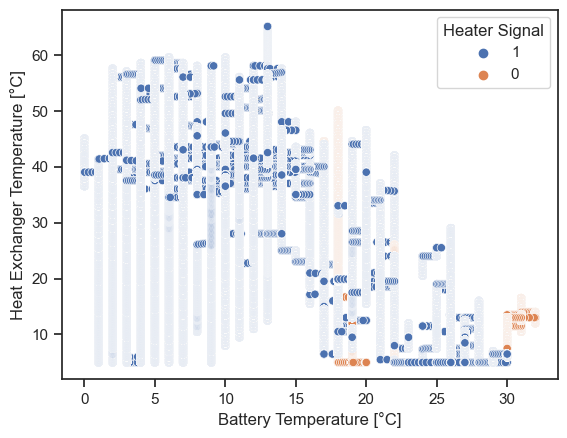

In [140]:
# Battery temp. , Heat exch. temp and heater signal
sns.scatterplot(data=outer_merged, x="Battery Temperature [°C]",y="Heat Exchanger Temperature [°C]", hue="Heater Signal")

In [ ]:
# # Battery Current, Motor torque and heater signal

# sns.scatterplot(data=outer_merged, x="Battery Current [A]",y="Motor Torque [Nm]", hue="Heater Signal")

In [ ]:
# # Heat exch. temp, ambient temp. and heater signal

# sns.scatterplot(data=outer_merged, x="Ambient Temperature [°C]",y="Heat Exchanger Temperature [°C]", hue="Heater Signal")

In [ ]:
# # Heat exch. temp, ambient temp. and heater signal

# sns.scatterplot(data=outer_merged, x="Ambient Temperature (Start) [°C]",y="Heat Exchanger Temperature [°C]", hue="Heater Signal")

In [165]:
# import matplotlib.pyplot as plt
# plt.scatter(outer_merged['Time [s]'], outer_merged['Heat Exchanger Temperature [°C]'], c='Heater Signal')
# plt.show()

## Checking multicolinearity

In [133]:
# Creating a df only for numerical columns
numerical_df = outer_merged.select_dtypes(include=np.number)

In [135]:
# Corealtion matrix
numerical_df.corr()
corr = numerical_df.corr()

<AxesSubplot: >

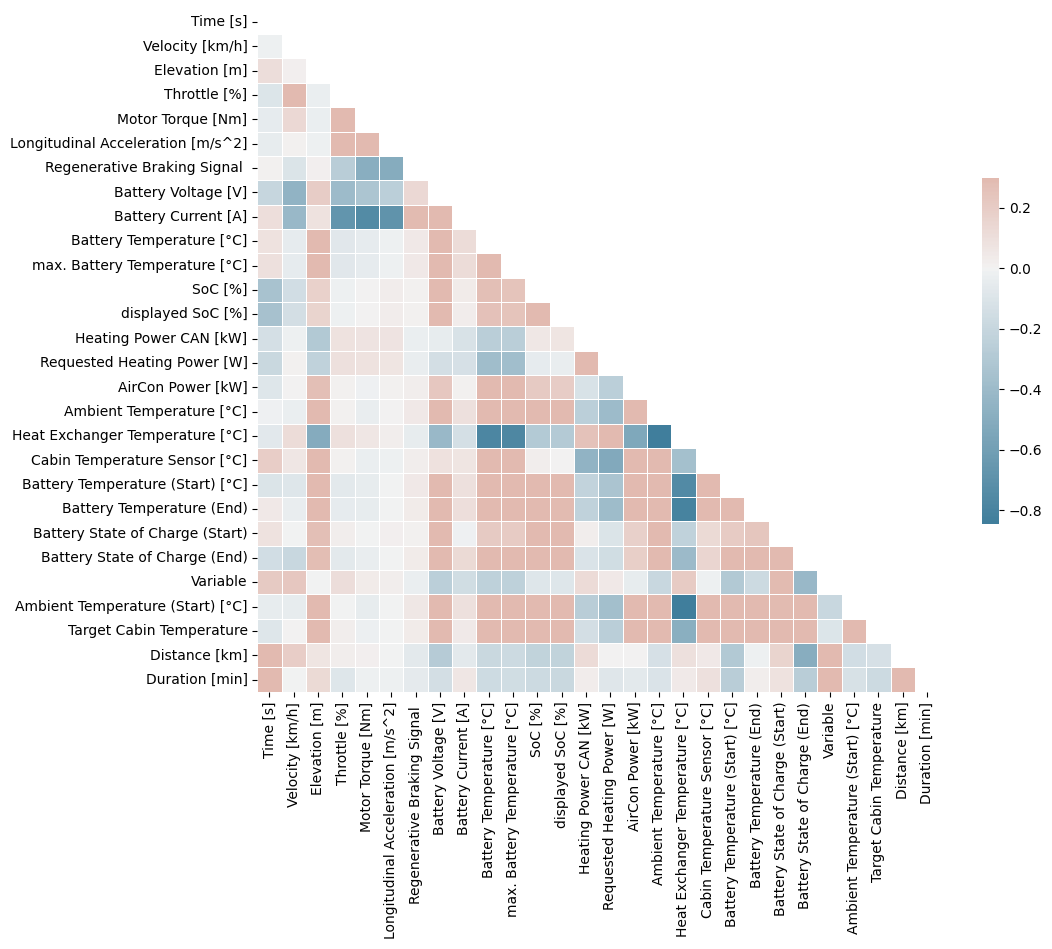

In [137]:
# Heatmap of the corelation matrix

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=.3, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

In [145]:
# Calculating VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# 1. Add a constant column to the DataFrame (required for VIF calculation)
X = add_constant(numerical_df)

# 2. Calculate VIF for each feature
vif = pd.DataFrame()
vif["Feature"] = X.columns
vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

# 3. Drop the constant column from the result
vif = vif[vif["Feature"] != "const"]

# Display VIF values
print(vif)

                              Feature         VIF
1                            Time [s]    4.218342
2                     Velocity [km/h]    3.367936
3                       Elevation [m]    1.904894
4                        Throttle [%]    3.338532
5                   Motor Torque [Nm]   19.095991
6   Longitudinal Acceleration [m/s^2]   17.327860
7        Regenerative Braking Signal     1.439652
8                 Battery Voltage [V]   30.026227
9                 Battery Current [A]    9.447653
10           Battery Temperature [°C]  266.481049
11      max. Battery Temperature [°C]  225.235785
12                            SoC [%]  166.715041
13                  displayed SoC [%]  154.206358
14             Heating Power CAN [kW]    2.147326
15        Requested Heating Power [W]    2.232756
16                  AirCon Power [kW]    2.002964
17           Ambient Temperature [°C]   20.555278
18    Heat Exchanger Temperature [°C]    4.593405
19      Cabin Temperature Sensor [°C]    2.444577


-  Battery Temperature [°C]  266.4810    max. Battery Temperature [°C]  225.23578   SoC [%]  166.7150    displayed SoC [%]  154.206  Ambient Temperature [°C]   20.555278 Battery Temperature (Start) [°C]   31.589733  Battery Temperature (End)   28.460482    Battery State of Charge (Start  13.3744    Battery State of Charge (End)   14.687 Motor Torque [Nm]   19.095991  Longitudinal Acceleration [m/s^2]   17.32786 Battery Voltage [V]   30.026227 **Shall be removed due to high multicollinearity**
-  Battery current and Voltage will be used to create a new variable that way we can save one important feature.0947358

## Feature Engineering

### 1. One hot encoding

In [124]:
# One hot encoding
one_hot_encoded_data = pd.get_dummies(outer_merged, columns = ['min. SoC [%]', 'max. SoC [%)', 'Requested Coolant Temperature [°C]', 'Route/Area', 'Weather', 'Fan', 'Note'])
one_hot_encoded_data.head()

,Time [s],Velocity [km/h],Elevation [m],Throttle [%],Motor Torque [Nm],Longitudinal Acceleration [m/s^2],Regenerative Braking Signal,Battery Voltage [V],Battery Current [A],Battery Temperature [°C],...,Note_FTM Route (directly after previous trip),Note_FTMRoute,Note_FTMRoute (directly after previous trip),"Note_Fast Charging, '+70 kg",Note_Open door at 37:10 and 42:00 for 30s,Note_Other,Note_Rush Hour,Note_Sunday -> little traffic,"Note_Sunday -> little traffic, (directly after previous trip)",Note_Target Cabin Temperature changed
0,0.0,0.0,574.0,0.0,0.0,-0.03,0.0,391.4,-2.20,21.0,...,False,False,False,False,False,True,False,False,False,False
1,0.1,0.0,574.0,0.0,0.0,0.00,0.0,391.4,-2.21,21.0,...,False,False,False,False,False,True,False,False,False,False
2,0.2,0.0,574.0,0.0,0.0,-0.01,0.0,391.4,-2.26,21.0,...,False,False,False,False,False,True,False,False,False,False
3,0.3,0.0,574.0,0.0,0.0,-0.03,0.0,391.4,-2.30,21.0,...,False,False,False,False,False,True,False,False,False,False
4,0.4,0.0,574.0,0.0,0.0,-0.03,0.0,391.4,-2.30,21.0,...,False,False,False,False,False,True,False,False,False,False


<AxesSubplot: >

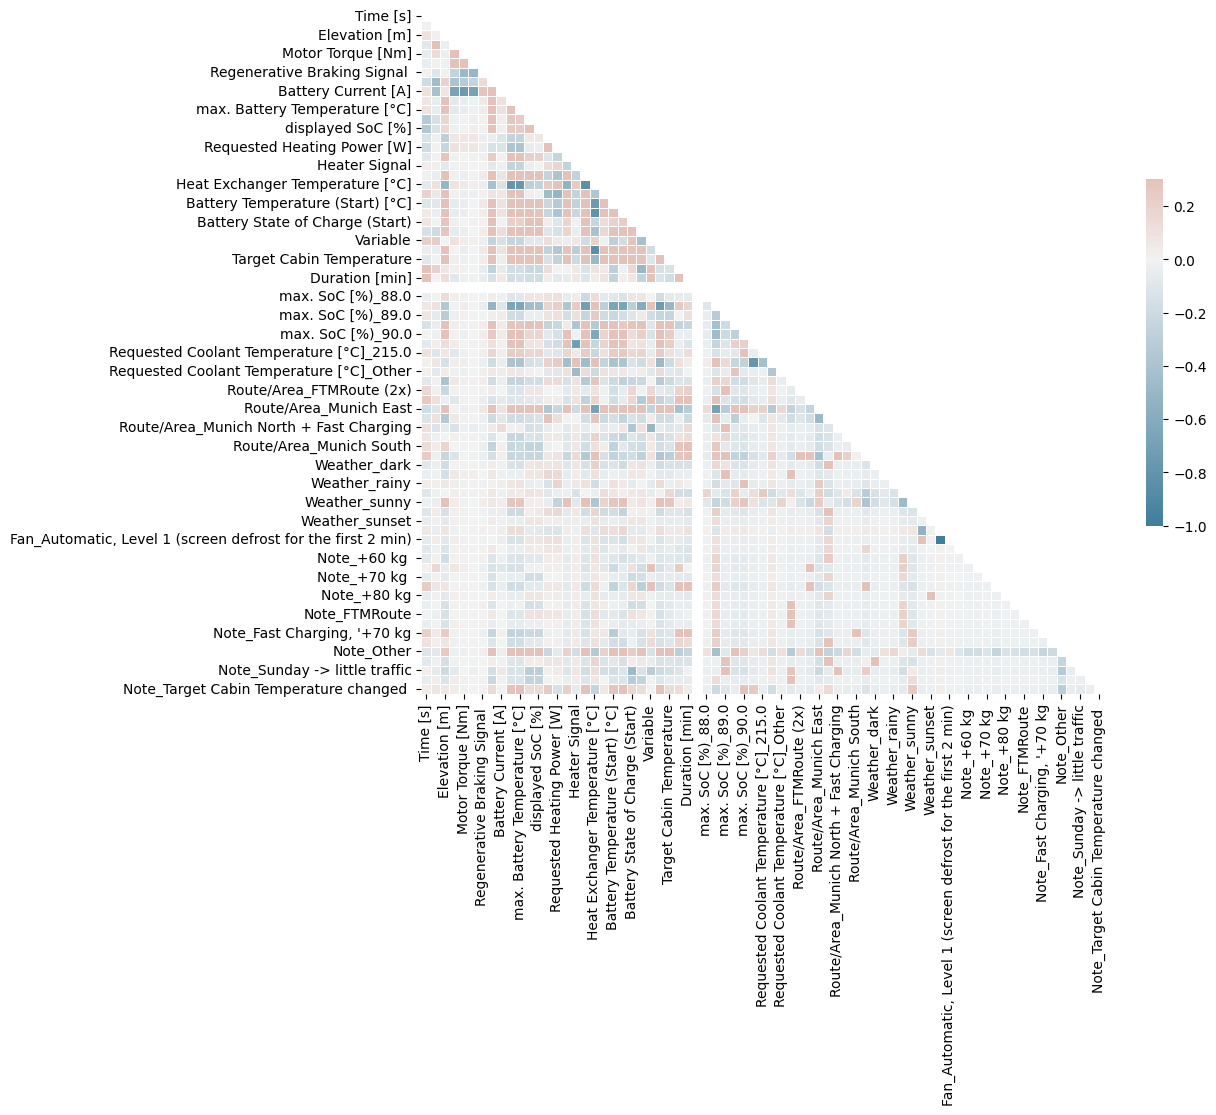

In [151]:
# One-hot encode categorical variables
correlation_matrix_categorial = one_hot_encoded_data.corr()

## Heatmap
# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(correlation_matrix_categorial, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(correlation_matrix_categorial, mask=mask, cmap=cmap, vmax=.3, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

In [162]:
# Set a threshold for high correlation (absolute value)
threshold = 0.8

# Find feature pairs with high correlation
high_corr_pairs = []

# Iterate over the correlation matrix
for i in range(len(correlation_matrix_categorial.columns)):
    for j in range(i + 1, len(correlation_matrix_categorial.columns)):
        if abs(correlation_matrix_categorial.iloc[i, j]) > threshold:
            feature_1 = correlation_matrix_categorial.columns[i]
            feature_2 = correlation_matrix_categorial.columns[j]
            correlation_value = correlation_matrix_categorial.iloc[i, j]
            high_corr_pairs.append((feature_1, feature_2, correlation_value))

# Convert to DataFrame for better readability
high_corr_df = pd.DataFrame(high_corr_pairs, columns=["Feature 1", "Feature 2", "Correlation Coefficient"])
high_corr_df

,Feature 1,Feature 2,Correlation Coefficient
0,Motor Torque [Nm],Longitudinal Acceleration [m/s^2],0.960423
1,Battery Voltage [V],SoC [%],0.802795
2,Battery Temperature [°C],max. Battery Temperature [°C],0.997225
3,Battery Temperature [°C],Ambient Temperature [°C],0.868937
4,Battery Temperature [°C],Battery Temperature (Start) [°C],0.961821
5,Battery Temperature [°C],Battery Temperature (End),0.942776
6,Battery Temperature [°C],Ambient Temperature (Start) [°C],0.888187
7,max. Battery Temperature [°C],Ambient Temperature [°C],0.858229
8,max. Battery Temperature [°C],Battery Temperature (Start) [°C],0.955639
9,max. Battery Temperature [°C],Battery Temperature (End),0.941139


> The results from VIF and correlation matrix indicate the variables that needs to be removed especially since linear models like logistic regression models where coefffecients are estimated directly. Secondly, multicollinearity makes it difficult to assess individual contributions.

In [238]:
# Dropping columns
battery_df = one_hot_encoded_data.drop(columns=['Battery Temperature [°C]','max. Battery Temperature [°C]', 'Ambient Temperature [°C]', 'Battery Temperature (Start) [°C]', 'Battery Temperature (End)', 'SoC [%]','displayed SoC [%]', 'Battery State of Charge (Start)', 'Battery State of Charge (End)', 'Motor Torque [Nm]', 'Longitudinal Acceleration [m/s^2]', 'Ambient Temperature (Start) [°C]', 'Distance [km]'])

In [240]:
battery_df.columns

Index(['Time [s]', 'Velocity [km/h]', 'Elevation [m]', 'Throttle [%]',
       'Regenerative Braking Signal ', 'Battery Voltage [V]',
       'Battery Current [A]', 'Heating Power CAN [kW]',
       'Requested Heating Power [W]', 'AirCon Power [kW]', 'Heater Signal',
       'Heat Exchanger Temperature [°C]', 'Cabin Temperature Sensor [°C]',
       'Variable', 'Target Cabin Temperature', 'Duration [min]',
       'min. SoC [%]_8.0', 'max. SoC [%)_88.0', 'max. SoC [%)_88.5',
       'max. SoC [%)_89.0', 'max. SoC [%)_89.5', 'max. SoC [%)_90.0',
       'Requested Coolant Temperature [°C]_0.0',
       'Requested Coolant Temperature [°C]_215.0',
       'Requested Coolant Temperature [°C]_85.0',
       'Requested Coolant Temperature [°C]_Other', 'Route/Area_FTMRoute',
       'Route/Area_FTMRoute (2x)', 'Route/Area_Highway',
       'Route/Area_Munich East', 'Route/Area_Munich North',
       'Route/Area_Munich North + Fast Charging',
       'Route/Area_Munich Northeast', 'Route/Area_Munich South',


In [250]:
# Adding 'resistance' column
battery_df['Resistance'] = (battery_df['Battery Voltage [V]'] / battery_df['Battery Current [A]'])

In [259]:
battery_df = battery_df.drop(columns=['Battery Voltage [V]','Battery Current [A]'])

In [261]:
battery_df.columns

Index(['Time [s]', 'Velocity [km/h]', 'Elevation [m]', 'Throttle [%]',
       'Regenerative Braking Signal ', 'Heating Power CAN [kW]',
       'Requested Heating Power [W]', 'AirCon Power [kW]', 'Heater Signal',
       'Heat Exchanger Temperature [°C]', 'Cabin Temperature Sensor [°C]',
       'Variable', 'Target Cabin Temperature', 'Duration [min]',
       'min. SoC [%]_8.0', 'max. SoC [%)_88.0', 'max. SoC [%)_88.5',
       'max. SoC [%)_89.0', 'max. SoC [%)_89.5', 'max. SoC [%)_90.0',
       'Requested Coolant Temperature [°C]_0.0',
       'Requested Coolant Temperature [°C]_215.0',
       'Requested Coolant Temperature [°C]_85.0',
       'Requested Coolant Temperature [°C]_Other', 'Route/Area_FTMRoute',
       'Route/Area_FTMRoute (2x)', 'Route/Area_Highway',
       'Route/Area_Munich East', 'Route/Area_Munich North',
       'Route/Area_Munich North + Fast Charging',
       'Route/Area_Munich Northeast', 'Route/Area_Munich South',
       'Weather_cloudy', 'Weather_dark', 'Weather_dar

- **test train dataset will be made from battery_df**

## Class imbalance detection

In [267]:
# calculating percentage of value counts in target variable 'Heat Signal'
battery_df['Heater Signal'].value_counts() * 100 / len(outer_merged)

Heater Signal
1    92.111076
0     7.888924
Name: count, dtype: float64

In [269]:
battery_df['Heater Signal'].value_counts()

Heater Signal
1    964928
0     82642
Name: count, dtype: int64

> Presence of imbalance. Treating it with 'Random Oversampling' as we would lose important data by removing data using 'Randon Undersampling'

In [275]:
battery_df.columns

Index(['Time [s]', 'Velocity [km/h]', 'Elevation [m]', 'Throttle [%]',
       'Regenerative Braking Signal ', 'Heating Power CAN [kW]',
       'Requested Heating Power [W]', 'AirCon Power [kW]', 'Heater Signal',
       'Heat Exchanger Temperature [°C]', 'Cabin Temperature Sensor [°C]',
       'Variable', 'Target Cabin Temperature', 'Duration [min]',
       'min. SoC [%]_8.0', 'max. SoC [%)_88.0', 'max. SoC [%)_88.5',
       'max. SoC [%)_89.0', 'max. SoC [%)_89.5', 'max. SoC [%)_90.0',
       'Requested Coolant Temperature [°C]_0.0',
       'Requested Coolant Temperature [°C]_215.0',
       'Requested Coolant Temperature [°C]_85.0',
       'Requested Coolant Temperature [°C]_Other', 'Route/Area_FTMRoute',
       'Route/Area_FTMRoute (2x)', 'Route/Area_Highway',
       'Route/Area_Munich East', 'Route/Area_Munich North',
       'Route/Area_Munich North + Fast Charging',
       'Route/Area_Munich Northeast', 'Route/Area_Munich South',
       'Weather_cloudy', 'Weather_dark', 'Weather_dar

In [309]:
X = battery_df[['Time [s]', 'Velocity [km/h]', 'Elevation [m]', 'Throttle [%]',
       'Regenerative Braking Signal ', 'Heating Power CAN [kW]',
       'Requested Heating Power [W]', 'AirCon Power [kW]', 'Heat Exchanger Temperature [°C]', 'Cabin Temperature Sensor [°C]',
       'Variable', 'Target Cabin Temperature', 'Duration [min]',
       'min. SoC [%]_8.0', 'max. SoC [%)_88.0', 'max. SoC [%)_88.5',
       'max. SoC [%)_89.0', 'max. SoC [%)_89.5', 'max. SoC [%)_90.0',
       'Requested Coolant Temperature [°C]_0.0',
       'Requested Coolant Temperature [°C]_215.0',
       'Requested Coolant Temperature [°C]_85.0',
       'Requested Coolant Temperature [°C]_Other', 'Route/Area_FTMRoute',
       'Route/Area_FTMRoute (2x)', 'Route/Area_Highway',
       'Route/Area_Munich East', 'Route/Area_Munich North',
       'Route/Area_Munich North + Fast Charging',
       'Route/Area_Munich Northeast', 'Route/Area_Munich South',
       'Weather_cloudy', 'Weather_dark', 'Weather_dark, little rainy',
       'Weather_rainy', 'Weather_slightly cloudy', 'Weather_sunny',
       'Weather_sunrise', 'Weather_sunset', 'Fan_Automatic, Level 1',
       'Fan_Automatic, Level 1 (screen defrost for the first 2 min)',
       'Note_+ 160 kg', 'Note_+60 kg ', 'Note_+70 kg', 'Note_+70 kg ',
       'Note_+70kg', 'Note_+80 kg',
       'Note_FTM Route (directly after previous trip)', 'Note_FTMRoute',
       'Note_FTMRoute (directly after previous trip)',
       "Note_Fast Charging, '+70 kg",
       'Note_Open door at 37:10 and 42:00 for 30s', 'Note_Other',
       'Note_Rush Hour', 'Note_Sunday -> little traffic',
       'Note_Sunday -> little traffic, (directly after previous trip)',
       'Note_Target Cabin Temperature changed ', 'Resistance']]

y = battery_df[['Heater Signal']]

## Test and train split


In [311]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [313]:
X_train.shape

(701871, 58)

In [315]:
X_test.shape

(345699, 58)

In [317]:
y_train.shape

(701871, 1)

In [319]:
y_test.shape

(345699, 1)

In [321]:
# Random Oversampling
from imblearn.over_sampling import SMOTE
# Resampling the minority class. The strategy can be changed as required.
sm = SMOTE(sampling_strategy='minority', random_state=42)

In [349]:
import numpy as np

# Replace infinities with NaN, then handle them as needed
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_train = X_train.fillna(0)  # Fill NaNs if created by infinite replacements

# Replace infinities with NaN, then handle them as needed
X_test = X_test.replace([np.inf, -np.inf], np.nan)
X_test = X_test.fillna(0)  # Fill NaNs if created by infinite replacements

In [325]:
oversample = SMOTE()
X_trainover, y_trainover = oversample.fit_resample(X_train, y_train)

In [337]:
# Fit the model to generate the data.
oversampled = pd.concat([X_trainover, y_trainover], axis=1)

In [341]:
# calculating percentage of value counts in target variable 'Heat Signal'
oversampled['Heater Signal'].value_counts() * 100 / len(oversampled)

Heater Signal
1    50.0
0    50.0
Name: count, dtype: float64

## Statistical analysis on numerical variables

In [144]:
# Slicing based on numerical columns of df

numerical_df = oversampled.select_dtypes(include=np.number)

# printing shape of the columns
print("Shape",numerical_df.shape)

# printing dtypes
print(numerical_df.dtypes)

Shape (1929856, 28)
Time [s]                             float64
Velocity [km/h]                      float64
Elevation [m]                        float64
Throttle [%]                         float64
Motor Torque [Nm]                    float64
Longitudinal Acceleration [m/s^2]    float64
Regenerative Braking Signal          float64
Battery Voltage [V]                  float64
Battery Current [A]                  float64
Battery Temperature [°C]             float64
max. Battery Temperature [°C]        float64
SoC [%]                              float64
displayed SoC [%]                    float64
Heating Power CAN [kW]               float64
Requested Heating Power [W]          float64
AirCon Power [kW]                    float64
Ambient Temperature [°C]             float64
Heat Exchanger Temperature [°C]      float64
Cabin Temperature Sensor [°C]        float64
Battery Temperature (Start) [°C]     float64
Battery Temperature (End)            float64
Battery State of Charge (Start)    

In [146]:
numerical_df.describe()

,Time [s],Velocity [km/h],Elevation [m],Throttle [%],Motor Torque [Nm],Longitudinal Acceleration [m/s^2],Regenerative Braking Signal,Battery Voltage [V],Battery Current [A],Battery Temperature [°C],...,Cabin Temperature Sensor [°C],Battery Temperature (Start) [°C],Battery Temperature (End),Battery State of Charge (Start),Battery State of Charge (End),Variable,Ambient Temperature (Start) [°C],Target Cabin Temperature,Distance [km],Duration [min]
count,1.929856e+06,1.929856e+06,1.929856e+06,1.929856e+06,1.929856e+06,1.929856e+06,1.929856e+06,1.929856e+06,1.929856e+06,1.929856e+06,...,1.929856e+06,1.929856e+06,1.929856e+06,1.929856e+06,1.929856e+06,1.929856e+06,1.929856e+06,1.929856e+06,1.929856e+06,1.929856e+06
mean,9.250840e+02,4.446276e+01,5.358579e+02,2.897859e+01,1.029530e+01,7.103592e-03,5.193885e-02,3.778778e+02,-1.797575e+01,1.865514e+01,...,2.608360e+01,1.753971e+01,1.943371e+01,7.419781e+01,5.984014e+01,1.480913e+01,1.738550e+01,2.420750e+01,2.302744e+01,3.155545e+01
std,6.691352e+02,3.517138e+01,3.558838e+01,1.764972e+01,3.409006e+01,6.243500e-01,2.199270e-01,1.051529e+01,3.849322e+01,7.222306e+00,...,5.450594e+00,7.846088e+00,6.253758e+00,1.142445e+01,1.610228e+01,1.197645e+01,1.012188e+01,2.730021e+00,1.378471e+01,1.386266e+01
min,0.000000e+00,0.000000e+00,4.370000e+02,0.000000e+00,-8.790000e+01,-9.030000e+00,0.000000e+00,3.018000e+02,-4.043800e+02,0.000000e+00,...,1.000000e+01,0.000000e+00,5.000000e+00,3.150000e+01,1.540000e+01,-2.410000e+01,-3.000000e+00,2.100000e+01,2.780000e+00,5.910000e+00
25%,3.956000e+02,1.582000e+01,5.090000e+02,1.512098e+01,0.000000e+00,-2.300000e-01,0.000000e+00,3.710200e+02,-2.964000e+01,1.400000e+01,...,2.334000e+01,1.200000e+01,1.500000e+01,6.750000e+01,4.600000e+01,7.800000e+00,7.500000e+00,2.200000e+01,1.432000e+01,2.374000e+01
50%,8.093731e+02,3.901705e+01,5.382900e+02,3.376147e+01,6.560000e+00,-9.760000e-03,0.000000e+00,3.810625e+02,-1.063599e+01,1.900000e+01,...,2.534000e+01,1.800000e+01,2.000000e+01,7.550000e+01,6.370000e+01,1.050000e+01,1.900000e+01,2.300000e+01,1.673000e+01,2.866000e+01
75%,1.334455e+03,6.629000e+01,5.625400e+02,4.283748e+01,2.232000e+01,2.218601e-01,0.000000e+00,3.854381e+02,-1.934503e+00,2.200000e+01,...,2.951000e+01,2.200000e+01,2.200000e+01,8.480000e+01,7.020000e+01,2.210000e+01,2.350000e+01,2.600000e+01,3.222000e+01,3.489000e+01
max,3.821800e+03,1.522600e+02,6.649900e+02,1.352500e+02,2.495000e+02,4.460000e+00,1.000000e+00,3.947585e+02,1.444900e+02,3.200000e+01,...,3.984130e+01,3.000000e+01,3.000000e+01,8.850000e+01,8.290000e+01,7.190000e+01,3.350000e+01,3.300000e+01,6.097000e+01,9.350000e+01


# Running Logistic Regression

In [345]:
# Base model with the trainover df

clf = LogisticRegression(random_state=42).fit(X_trainover, y_trainover)

C:\Users\Anurodh\anaconda3\lib\site-packages\sklearn\utils\validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\Anurodh\anaconda3\lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [351]:
# Predicting on X_test

y_pred = clf.predict(X_test)

In [353]:
# Prediction probability

y_proba = clf.predict_proba(X_test)

In [359]:
# Confusion matrix

confusion_matrix(y_test, y_pred)

array([[ 25667,   1454],
       [ 27751, 290827]], dtype=int64)

In [361]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

In [363]:
# Accuracy, precision and recall

acc = (tp+tn)/(tp+tn+fn+fp)
prec = tp/(tp+fp)
recall = tp/(tp+fn)

print("Accuracy", acc)
print("Precision", prec)
print("Recall", recall)

Accuracy 0.9155189919554294
Precision 0.9950253352082414
Recall 0.9128910345347137


In [365]:
# Calculate R2
r2_score(y_test, y_pred)

-0.16851382133326065

In [ ]:
# Coeffecients Logistic Regression
# print(clf.coef_, clf.intercept_)

In [367]:
# Print coefficients with feature names
dic_LR_coef = {}
feature_list = []
coeff_list = []
for feature, coef in zip(X_train.columns, clf.coef_[0]):
    # print(f"{feature}: {coef}")
    dic_LR_coef[feature] = coef
    feature_list.append(feature)
    coeff_list.append(coef)

In [369]:
sorted_dic_LR_coef = dict(sorted(dic_LR_coef.items(), key=lambda item: item[1], reverse=True))
sorted_dic_LR_coef

{'Requested Heating Power [W]': 2.7138086089944613,
 'Requested Coolant Temperature [°C]_85.0': 1.0531424002750678,
 'Target Cabin Temperature': 0.4094752116917946,
 'max. SoC [%)_90.0': 0.2505483137072097,
 'Heating Power CAN [kW]': 0.2316592280828575,
 'Weather_rainy': 0.07731097646193219,
 'Weather_sunny': 0.055052414811938497,
 'Route/Area_Munich East': 0.05134822702275337,
 'Variable': 0.03618456936063304,
 'max. SoC [%)_88.5': 0.030898156182501253,
 'Weather_cloudy': 0.030270475339470575,
 'max. SoC [%)_89.0': 0.021489951449239847,
 'Note_Sunday -> little traffic': 0.02060420800157313,
 'Route/Area_Munich North + Fast Charging': 0.01936743236504956,
 'Route/Area_Munich South': 0.015551853784979343,
 "Note_Fast Charging, '+70 kg": 0.015450683207139038,
 'Route/Area_Highway': 0.0098965598646934,
 'Requested Coolant Temperature [°C]_215.0': 0.0052816172827574144,
 'Velocity [km/h]': 0.0029720907193749348,
 'Heat Exchanger Temperature [°C]': 0.002058116062802624,
 'max. SoC [%)_88.0'

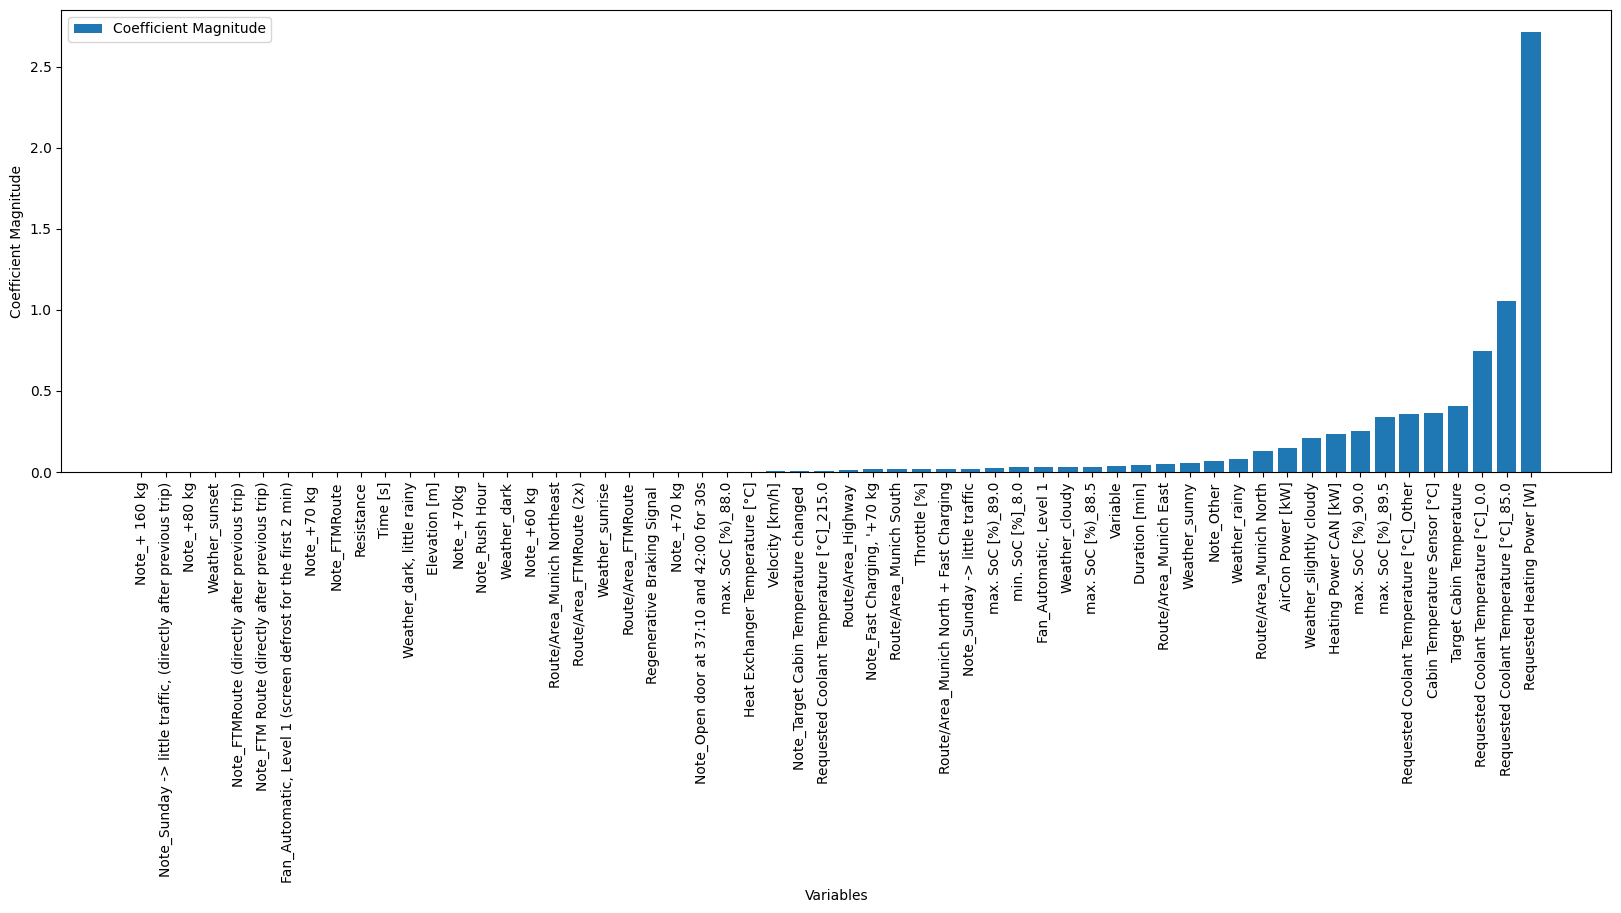

In [384]:
# library & dataset
import matplotlib.pyplot as plt

df=pd.DataFrame({'coefficient':np.abs(coeff_list),'variables':feature_list})
df.sort_values('coefficient',inplace=True)

plt.figure(figsize=(20,6))
plt.bar(df.variables,df.coefficient,label='Coefficient Magnitude')
# Rotate y-tick labels by 45 degrees
plt.xticks(rotation=90)

# Adding labels and legend
plt.xlabel('Variables')  # x-axis label
plt.ylabel('Coefficient Magnitude')  # y-axis label
plt.legend()  # Add legend

plt.show()

- **Alternative Model Comparison**: Implement a decision tree model as an alternative to the logistic regression model, enabling comparison of results and selection of the best-performing model.

- **Data Exploration and Model Selection**: Perform stratified random sampling and plot a scatter plot matrix to understand data separation. This will inform the decision on whether linear or non-linear models are more suitable.

- **K-Fold Cross Validation**: Use K-fold cross-validation (likely `k=10`) to achieve a more generalized accuracy metric.

- **Feature Engineering for Numerical Columns**: Convert specific numerical columns to categorical variables where apprsackets) to capture non-linear relationships.

- **Pruning of Less Desirable Features**: Identify and remove less relevant features to improve model generalization and minimize potential bias.

- **Identification of Key Variables**: Determine important variables that would be valuable in future data collection and experimental design, focusing on insights for enhancing predictive power.

- **Application to Battery Heating Prediction**: Utilize this framework as a baseline for developing models aimed at predicting battery heating, potentially adapting feature engineering, data exploration, and validation steps specific to this application.
  
- **Domain  Knowledge**: Study about the features of the dataset and understand relationships between the features and how they are interrelated. How their combination affects the target variable. For example: presence of multicollienarity in Battery Current and Voltage led me to create another feature 'Resistance'. Also explore other variable like 'Battery temp. end' as the target variable.

# Future recommendations
- Alternate model for ex- decision tree to compare the results and to later choose the best among the two.

decision tree parametric or non?

log regression parametric, linear or non-linear?

Will perform stratified random sampling and plot scatter plot matrix to understand separation in data. This will help choosing between linear, non linear models. 

K-fold cross validation  to gain more genralised accuracy most likely k=10. 

(logistic regression- base line is the best- simple and easy to explain, computational requirement less)

Feature engineering of numerical columns coverted to categorical (and add example)

Pruning of less desirable features to get more genraized model and remove any bias

Understand imporant variables to use in future data collection and experimental design

Use this framework as the baseline for the development of battery heating prediction